<a href="https://colab.research.google.com/github/mohamedrafat9/DL/blob/main/airline_delay_cause.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install opendatasets
import opendatasets as od


In [2]:
od.download("https://www.kaggle.com/datasets/y0usef/airline-delay-cause-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: mohamedrafat1
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/y0usef/airline-delay-cause-dataset


100%|██████████| 10.5M/10.5M [00:00<00:00, 990MB/s]

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
data=pd.read_csv("/content/airline-delay-cause-dataset/Airline_Delay_Cause.csv")
data

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,DL,Delta Air Lines Inc.,SEA,"Seattle, WA: Seattle/Tacoma International",480.0,84.0,25.69,3.09,...,0.0,21.26,0.0,0.0,3744.0,978.0,164.0,1023.0,0.0,1579.0
318013,2003,6,DL,Delta Air Lines Inc.,SFO,"San Francisco, CA: San Francisco International",505.0,111.0,21.78,2.24,...,0.0,13.17,3.0,0.0,4284.0,1376.0,138.0,2132.0,0.0,638.0
318014,2003,6,DL,Delta Air Lines Inc.,SJC,"San Jose, CA: Norman Y. Mineta San Jose Intern...",146.0,36.0,6.99,0.00,...,0.0,2.15,0.0,0.0,896.0,205.0,0.0,607.0,0.0,84.0
318015,2003,6,DL,Delta Air Lines Inc.,SJU,"San Juan, PR: Luis Munoz Marin International",95.0,13.0,3.66,0.00,...,0.0,1.42,0.0,0.0,367.0,120.0,0.0,210.0,0.0,37.0


In [5]:
print(data.shape)
data.info()

(318017, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   carrier              318013 non-null  object 
 3   carrier_name         318013 non-null  object 
 4   airport              318014 non-null  object 
 5   airport_name         318017 non-null  object 
 6   arr_flights          317524 non-null  float64
 7   arr_del15            317285 non-null  float64
 8   carrier_ct           317525 non-null  float64
 9   weather_ct           317523 non-null  float64
 10  nas_ct               317529 non-null  float64
 11  security_ct          317529 non-null  float64
 12  late_aircraft_ct     317529 non-null  float64
 13  arr_cancelled        317529 non-null  float64
 14  arr_diverted         317527 non-null  float64
 15  arr_

In [6]:
# print(data['carrier'].value_counts().unique())
# print(data['carrier_name'].value_counts().unique())
# print(data['airport'].value_counts().unique())
print(data['airport_name'].value_counts().unique())


[3022 2990 2978 2967 2951 2937 2934 2932 2919 2914 2899 2898 2890 2865
 2859 2850 2842 2807 2736 2707 2704 2690 2686 2677 2672 2636 2626 2622
 2609 2600 2581 2566 2557 2547 2486 2468 2460 2458 2380 2371 2343 2332
 2301 2300 2265 2242 2207 2203 2176 2111 2103 2099 2071 2067 2039 2038
 2025 2017 1986 1980 1962 1955 1916 1882 1880 1858 1847 1838 1769 1757
 1744 1689 1648 1628 1618 1605 1600 1597 1530 1526 1518 1516 1478 1455
 1443 1440 1413 1402 1390 1362 1361 1340 1333 1324 1310 1304 1277 1263
 1234 1210 1205 1147 1125 1103 1078 1060 1053 1048 1039 1018  993  987
  977  968  956  955  934  924  911  906  904  901  900  887  876  866
  865  864  863  859  857  848  827  826  823  819  807  786  757  750
  739  724  723  711  692  685  672  657  654  650  638  624  614  607
  593  577  574  572  571  553  550  548  538  530  529  511  499  497
  494  491  490  487  482  473  470  462  460  458  440  430  422  412
  405  404  403  400  399  388  386  384  379  351  348  338  328  317
  312 

In [7]:
data.isnull().sum()

,0
year,0
month,0
carrier,4
carrier_name,4
airport,3
airport_name,0
arr_flights,493
arr_del15,732
carrier_ct,492
weather_ct,494


In [8]:
data.describe(include='all')

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,318017.000000,318017.000000,318013,318013,318014,318017,317524.000000,317285.000000,317525.000000,317523.000000,...,317529.000000,317529.000000,317529.000000,317527.000000,317523.000000,317525.000000,317529.000000,317529.000000,317527.000000,317529.000000
unique,NaN,NaN,29,33,420,420,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,OO,SkyWest Airlines Inc.,DTW,"Detroit, MI: Detroit Metro Wayne County",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,38145,38145,3022,3022,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012.450957,6.497844,NaN,NaN,NaN,NaN,381.766670,72.905076,21.073149,2.616407,...,0.179037,24.975734,7.207257,0.867674,4209.989113,1286.577224,220.567542,1099.516422,7.214845,1596.062993
std,5.678296,3.459423,NaN,NaN,NaN,NaN,1027.156722,198.936754,47.671580,9.968640,...,0.844834,75.275223,37.216301,3.915772,12519.021012,3515.417309,861.521440,4636.475908,38.854685,4924.950687
min,2003.000000,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-19.000000,0.000000,0.000000
25%,2007.000000,3.000000,NaN,NaN,NaN,NaN,59.000000,9.000000,3.000000,0.000000,...,0.000000,1.640000,0.000000,0.000000,436.000000,148.000000,0.000000,56.000000,0.000000,79.000000
50%,2012.000000,6.000000,NaN,NaN,NaN,NaN,120.000000,23.000000,8.190000,0.580000,...,0.000000,5.860000,1.000000,0.000000,1201.000000,437.000000,25.000000,203.000000,0.000000,351.000000
75%,2018.000000,10.000000,NaN,NaN,NaN,NaN,273.000000,56.000000,19.690000,2.000000,...,0.000000,17.040000,4.000000,1.000000,3080.000000,1100.000000,159.000000,602.000000,0.000000,1110.000000


In [9]:
data = data.drop(['carrier','carrier_name','airport','airport_name'],axis=1)

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318017 entries, 0 to 318016
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 318017 non-null  int64  
 1   month                318017 non-null  int64  
 2   arr_flights          317524 non-null  float64
 3   arr_del15            317285 non-null  float64
 4   carrier_ct           317525 non-null  float64
 5   weather_ct           317523 non-null  float64
 6   nas_ct               317529 non-null  float64
 7   security_ct          317529 non-null  float64
 8   late_aircraft_ct     317529 non-null  float64
 9   arr_cancelled        317529 non-null  float64
 10  arr_diverted         317527 non-null  float64
 11  arr_delay            317523 non-null  float64
 12  carrier_delay        317525 non-null  float64
 13  weather_delay        317529 non-null  float64
 14  nas_delay            317529 non-null  float64
 15  security_delay   

In [11]:
data.isnull().sum()

,0
year,0
month,0
arr_flights,493
arr_del15,732
carrier_ct,492
weather_ct,494
nas_ct,488
security_ct,488
late_aircraft_ct,488
arr_cancelled,488


In [12]:
data.dropna(inplace=True)
data

,year,month,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,136.0,7.0,5.95,0.00,0.05,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,91.0,16.0,7.38,0.00,2.54,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,19.0,2.0,0.13,0.00,1.00,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,88.0,14.0,7.26,0.76,4.35,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,181.0,19.0,13.84,0.00,3.07,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
318012,2003,6,480.0,84.0,25.69,3.09,33.96,0.0,21.26,0.0,0.0,3744.0,978.0,164.0,1023.0,0.0,1579.0
318013,2003,6,505.0,111.0,21.78,2.24,73.81,0.0,13.17,3.0,0.0,4284.0,1376.0,138.0,2132.0,0.0,638.0
318014,2003,6,146.0,36.0,6.99,0.00,26.85,0.0,2.15,0.0,0.0,896.0,205.0,0.0,607.0,0.0,84.0
318015,2003,6,95.0,13.0,3.66,0.00,7.92,0.0,1.42,0.0,0.0,367.0,120.0,0.0,210.0,0.0,37.0


In [13]:
data['weather_delay'].min(),data['weather_delay'].max()

(0.0, 57707.0)

In [14]:
data['weather_delay'].describe(include='all')

,weather_delay
count,317268.000000
mean,220.737197
std,861.851963
min,0.000000
25%,0.000000
50%,25.000000
75%,159.000000
max,57707.000000


In [15]:
data['WDCase'] = data['weather_delay'].apply(lambda x : 1 if x >100 else 0)

In [16]:
X = data.drop(['WDCase'],axis = 1)
y =data['WDCase']

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=44,
    shuffle =True
    )

In [18]:
import tensorflow as tf
from tensorflow import keras
KerasModel = keras.models.Sequential([
                # keras.layers.Input(shape=(17)),
            keras.layers.Dense(8,  activation = 'tanh'),
            # keras.layers.Dropout(0.1),
            keras.layers.Dense(128, activation = 'relu'),
            # keras.layers.Dropout(0.3),
            keras.layers.Dense(64, activation = 'tanh'),
            keras.layers.Dense(32, activation = 'tanh'),
            keras.layers.Dropout(0.2),
            keras.layers.Dense(1, activation = 'sigmoid')
            ])

In [19]:
from tensorflow.keras.optimizers import AdamW
MyOptimizer = AdamW(
    learning_rate=0.001,
    weight_decay=0.004,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-07,
    amsgrad=False,
    clipnorm=None,
    clipvalue=None,
    global_clipnorm=None,
    use_ema=False,
    ema_momentum=0.99,
    ema_overwrite_frequency=None,
    # jit_compile=True,
    name="AdamW")

In [20]:
print(tf.__version__)

2.19.0


In [21]:
KerasModel.compile(optimizer =MyOptimizer,
                   loss='binary_crossentropy',
                   metrics=['accuracy'],
                   jit_compile=True
                   )

In [22]:
history = KerasModel.fit(X_train,y_train,
                         validation_data=(X_test,y_test),
                         epochs=100,
                         batch_size=10000,
                         verbose=1,
                         callbacks=[tf.keras.callbacks.EarlyStopping(
                                            patience=10,
                                            monitor='val_accuracy',#"val_loss",
                                            restore_best_weights=True)])

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 175ms/step - accuracy: 0.7204 - loss: 0.5587 - val_accuracy: 0.8112 - val_loss: 0.4407
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8128 - loss: 0.4374 - val_accuracy: 0.8108 - val_loss: 0.4231
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8093 - loss: 0.4175 - val_accuracy: 0.8055 - val_loss: 0.4021
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8101 - loss: 0.3980 - val_accuracy: 0.8160 - val_loss: 0.3827
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8213 - loss: 0.3738 - val_accuracy: 0.8420 - val_loss: 0.3532
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8477 - loss: 0.3440 - val_accuracy: 0.8659 - val_loss: 0.3179
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8687 - loss: 0.3058 - val_accuracy: 0.8877 - val_loss: 0.2749
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.8895 - loss: 0.2630 - val_accuracy: 

In [23]:
print(KerasModel.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,997 (136.71 KB)

 Trainable params: 11,665 (45.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,332 (91.14 KB)

None


In [24]:
KerasModel.save('KerasModel.keras')

In [25]:
NewKerasModel = keras.models.load_model('KerasModel.keras')

In [26]:
y_pred = NewKerasModel.predict(X_test)
ModelLoss, ModelAccuracy = NewKerasModel.evaluate(X_test, y_test)
print('Model Loss is {}'.format(ModelLoss))
print('Model Accuracy is {}'.format(ModelAccuracy ))

2479/2479 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
2479/2479 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9983 - loss: 0.0068
Model Loss is 0.0067712003365159035
Model Accuracy is 0.9983609914779663


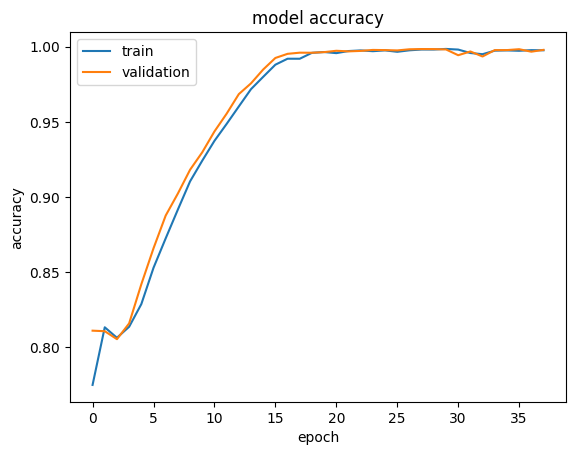

In [27]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

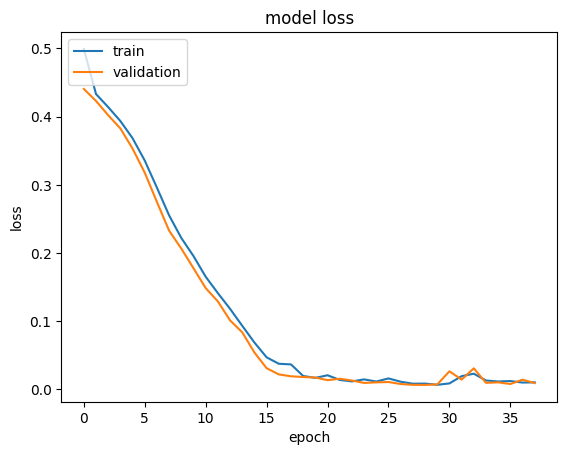

In [28]:
# "Loss"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [33]:
y_pred=[np.round(i[0]) for i in y_pred]
y_pred

[np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float32(0.0),
 np.float32(1.0),
 np.float32(1.0),
 np.float3

[[53698    26]
 [  104 25489]]


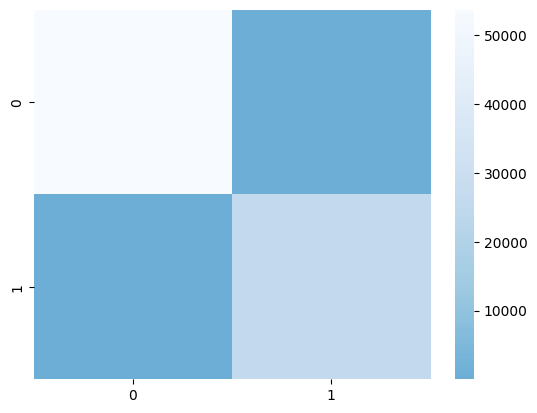

In [35]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
CM = confusion_matrix(y_test, y_pred)
print(CM)
sns.heatmap(CM, center = True,cmap='Blues_r')
plt.show()


In [36]:
from sklearn.metrics import classification_report
ClassificationReport = classification_report(y_test,y_pred)
print('Classification Report is : \n', ClassificationReport )

Classification Report is : 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     53724
           1       1.00      1.00      1.00     25593

    accuracy                           1.00     79317
   macro avg       1.00      1.00      1.00     79317
weighted avg       1.00      1.00      1.00     79317

